# 04 — Taxa manual da carteira

O mesmo fluxo do 03 (framework da SOA e monografia nº 5 da CAS), agora na carteira contra a BR-EMSmt 2026, com
**partição fora do tempo** como faz a SOA: treino com a experiência até 2023, teste em 2024.

$$
N_c \sim \text{Poisson}(\mu_c), \qquad \log \mu_c = \log E_c + \beta_0 + \beta_{cap}\,\log\frac{\text{capital}_c}{\text{ref}} + \beta_{\text{seção}(c)} + \dots
$$

| Candidato | Papel | Origem |
|---|---|---|
| Plano atual (tábua × A/E) | o que se compara | CAS 4.3.3 |
| GLM (capital e seção) | candidato a tarifa | SOA 4.1 |
| GLMM (+ efeito de divisão e de estipulante) | candidato a tarifa | adaptação: CAS 10.1 e evidência do 03 (grupos têm mortalidade própria) |
| Ridge com priori SOA | candidato a tarifa | adaptação: priori do estudo de mercado via penalização (SOA 4.3.1) |
| AGLM com priori SOA (capital linear por partes, faixas fundidas) | candidato a tarifa | Fujita et al. (2020) |
| GAM (curva suave do capital) | referência e diagnóstico de forma | Wood (2017), `mgcv` |
| Elastic net (LASSO) + interações do LightGBM | referência de desempenho | SOA 4.3 |
| LightGBM | referência de desempenho | SOA 4.2 |

Elastic net com interações e LightGBM não viram tarifa: não cabem numa tabela de fatores explicável nem na nota
técnica. Se uma referência ganhar de todos os candidatos com significância, isso sinaliza estrutura faltando; a
interação mais forte apontada pelo LightGBM é testada diretamente no GLMM (seção 4).

**Anos excluídos da experiência:** os de choque externo identificado (`excluir_anos_experiencia`; hoje, 2021),
com a evidência na seção 1.

**Regra de decisão** (fixada antes do teste, em `config/manual.yaml`): menor deviance no teste entre os candidatos a
tarifa; empates (IC de 95% da diferença, por bootstrap pareado **por estipulante**, contém zero) resolvidos pela
ordem de preferência. O escolhido é reajustado com toda a experiência maturada (CAS 4.3.3).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore", message="Efeitos aleatórios com variância nula")   # informado explicitamente abaixo
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, glmm as G, elasticnet as EN, diagnostico as D, avaliacao as A, prioris as PR
from vgpricing.graficos import estilo
estilo()

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cmo = (carregar_config(n, RAIZ) for n in ("base", "manual", "modelagem"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
assert not tabua.placeholder and G.r_disponivel(), "Precisa da tábua oficial e do R (veja o README)"
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
dados = {t: pd.read_parquet(limpo / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
prioris = M.carregar_tabela(RAIZ / "artefatos/prioris_soa.yaml")               # gerado no 03
FT = cm["fora_do_tempo"]
base = lambda janela: M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua,
                                       cfg["data_referencia"], cm, cfg["exposicao"]["dias_por_ano"], janela=janela,
                                       excluir_anos=tuple(cm["excluir_anos_experiencia"]))
tr, itr = base((None, FT["treino_ate"]))
te, ite = base(tuple(FT["teste"]))
secoes_treino = set(tr["cnae_secao"])
te["cnae_secao"] = te["cnae_secao_original"].where(te["cnae_secao_original"].isin(secoes_treino), "OUTRAS")
pd.DataFrame({"período": [f"até {itr['corte_experiencia']}", f"{ite['inicio_experiencia']} a {ite['corte_experiencia']}"],
              "óbitos": [itr["obitos"], ite["obitos"]], "esperados (tábua)": [itr["esperados"], ite["esperados"]],
              "estipulantes": [itr["estipulantes"], ite["estipulantes"]]}, index=["treino", "teste"])

,período,óbitos,esperados (tábua),estipulantes
treino,até 2023-12-31,2224,"2,127.4682",250
teste,2024-01-01 a 2024-12-31,562,557.3864,250


O teste usa o mapeamento de seções do treino (seções raras no treino viram "OUTRAS" nos dois).

## 1. Política para o ano de choque

Antes de comparar modelos, a escolha dos dados: o ano de choque (2021) entra ou sai da experiência? Mesma partição
fora do tempo e o mesmo GLM; muda só o treino. O estudo por ano-calendário (02) mostra 2021 fora do intervalo dos
demais anos.

In [2]:
from joblib import Memory
cache = Memory(RAIZ / "data/processed/cache", verbose=0).cache
base_exc = lambda janela, exc: M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua,
                                                cfg["data_referencia"], cm, janela=janela, excluir_anos=exc)
te_pol, _ = base_exc(tuple(FT["teste"]), ())
pol = {}
for nome, exc in [("manter 2021", ()), ("excluir 2021", (2021,))]:
    trp, _ = base_exc((None, FT["treino_ate"]), exc)
    tab = cache(M.ajustar_tabela)(trp, "GLM", cm, prioris, {})
    t2 = te_pol.assign(cnae_secao=te_pol["cnae_secao_original"].where(te_pol["cnae_secao_original"].isin(set(trp["cnae_secao"])), "OUTRAS"),
                       capital=cm["capital_referencia"] * np.exp(te_pol["log_capital_c"]))
    te_pol[f"mu_{nome}"] = t2["E"] * M.multiplicador_manual(t2, tab)[0]
    pol[nome] = f"mu_{nome}"
comp_pol = A.comparar_modelos(te_pol, pol, "manter 2021", unidade="id_estipulante")
comp_pol["A/M total no teste"] = [te_pol["N"].sum() / te_pol[c].sum() for c in pol.values()]
comp_pol

,modelo,deviance,diferença vs manter 2021,IC95 inf,IC95 sup,significativa,A/M total no teste
0,manter 2021,317.8052,0.0000,0.0000,0.0000,False,0.9059
1,excluir 2021,310.9474,-6.8578,-15.6708,2.3019,False,0.9646


Excluir 2021 reduz o viés de nível no teste (A/M total mais perto de 1); a diferença de deviance com um ano de teste
não é significativa, mas aponta na mesma direção do A/E por ano (02) e da evidência real do SES (05). Decisão:
`excluir_anos_experiencia: [2021]` em `config/manual.yaml`, aplicada daqui em diante.

## 2. GLM (SOA 4.1)

In [3]:
FIXOS = cm["modelo"]["fixos_obrigatorios"]
glm = M.ajustar_comparacao(tr, cm, FIXOS, "poisson")
an = G.ajustar_glmm(tr, FIXOS, [], categoricas=["cnae_secao"], numericas=["log_capital_c"],
                    niveis_base=M.niveis_base(tr, ["cnae_secao"]), anova=True).extra["anova"]
te["mu_glm"] = G.prever(glm, te)
print(f"Motor: {glm.extra['motor']} | dispersão de Pearson: {glm.extra['dispersao_pearson']:.3f}")
display(an)
glm.fixos.assign(fator=np.exp(glm.fixos["estimativa"]))

Motor: stats::glm | dispersão de Pearson: 1.322


,termo,gl,deviance,gl_residual,deviance_residual,p_valor
0,NULL,NaN,NaN,7453,"3,468.0577",NaN
1,log_capital_c,1.0000,6.5026,7452,"3,461.5551",0.0108
2,cnae_secao,9.0000,75.5680,7443,"3,385.9871",0.0000


,nome,estimativa,ep,fator
0,(Intercept),0.1013,0.0520,1.1067
1,log_capital_c,-0.0682,0.0244,0.9340
2,cnae_secaoF,0.1466,0.0836,1.1579
3,cnae_secaoG,-0.0312,0.0812,0.9692
4,cnae_secaoH,0.1645,0.0751,1.1788
5,cnae_secaoK,-0.2995,0.1413,0.7412
6,cnae_secaoM,-0.4362,0.0961,0.6465
7,cnae_secaoN,-0.0981,0.0795,0.9066
8,cnae_secaoO,-0.1886,0.0857,0.8281
9,cnae_secaoP,-0.3199,0.1100,0.7262


## 3. GLMM (adaptação: efeito de grupo)

O 03 mostrou, com dados reais, que grupos têm mortalidade própria além do que as variáveis explicam. Aqui o
estipulante é identificado, então entra como efeito aleatório; a divisão CNAE entra como efeito aleatório dentro da
seção (credibilidade de Ohlsson). Idade, sexo e porte são candidatos, testados por razão de verossimilhança com
correção de Holm.

In [4]:
glmm, _, testes = M.ajustar_taxa_manual(tr, cm)
te["mu_glmm"] = G.prever(glmm, te)
print("Fórmula:", glmm.formula)
print("Efeitos aleatórios retirados por variância nula (ajuste singular):", glmm.extra["aleatorios_removidos"] or "nenhum")
display(testes)
M.comparar_dispersao(tr, cm, glmm)

Fórmula: N ~ log_capital_c + cnae_secao + (1 | id_estipulante) + offset(log(E))
Efeitos aleatórios retirados por variância nula (ajuste singular): ['(1|cnae_secao:cnae_divisao)']


,termo,tipo,lr,gl,p_valor,p_holm,decisao
0,faixa_idade,fixo,8.0929,4,0.0882,0.1765,não entra
1,sexo,fixo,2.0169,2,0.3648,0.3648,não entra
2,faixa_tamanho,fixo,9.2567,3,0.0261,0.0782,não entra
3,(1|cnae_secao:cnae_divisao),aleatorio,0.0000,1,1.0000,NaN,estrutura (mantido)
4,(1|id_estipulante),aleatorio,92.2117,1,0.0000,NaN,estrutura (mantido)


,modelo,dispersão,loglik,parametros,AIC,dif_AIC_vs_melhor
0,GLM Poisson,nenhuma,"-3,024.6158",11,"6,071.2316",103.6694
1,Binomial Negativa (NB2),"por célula, independente","-3,010.0879",12,"6,044.1757",76.6135
2,GLMM (efeitos de divisão e estipulante),por grupo e por atividade,"-2,971.7811",12,"5,967.5622",0.0000


Com as log-verossimilhanças na mesma base (todas no mesmo pacote), o modelo com efeito de estipulante tem AIC menor
que a Binomial Negativa: a sobredispersão está no grupo, não na célula.

## 4. Ridge com priori SOA (adaptação)

A forma do estudo da SOA (elasticidade ao capital e fatores relativos de seção, 03a) entra no offset:

$$
\log \mu_c = \underbrace{\log E_c + \beta^{SOA}\log\tfrac{\text{capital}_c}{\text{ref}} + \log f^{SOA}_{\text{seção}(c)}}_{\text{offset}} + b_0 + \delta\,\log\tfrac{\text{capital}_c}{\text{ref}} + \gamma_{\text{seção}(c)} .
$$

A penalização ridge encolhe $\delta$ e $\gamma$ para zero, ou seja, para o estudo: é uma priori normal centrada na
SOA, e o lambda (validação cruzada por estipulante) faz o papel do k da credibilidade (SOA 4.3.1).

In [5]:
tr["fold"] = A.folds_por_grupo(tr["id_estipulante"], cm["validacao_cruzada"]["folds"], cm["validacao_cruzada"]["semente"]) + 1
for d in (tr, te):
    d["log_E"], d["off_priori"] = np.log(d["E"]), PR.offset_priori(d, prioris)
ridge = EN.ajustar_elastic_net(tr, {"teste": te}, ["log_capital_c", "cnae_secao"], ["cnae_secao"], ["log_capital_c"],
                               "off_priori", alpha=0.0, foldid="fold")
te["mu_ridge"] = ridge.previsoes["teste"]
pd.Series({"elasticidade SOA (priori)": prioris["elasticidade_capital"],
           "desvio estimado na carteira (δ)": ridge.coeficientes["log_capital_c"],
           "elasticidade final": prioris["elasticidade_capital"] + ridge.coeficientes["log_capital_c"],
           "elasticidade no GLM (sem priori)": glm.coef("log_capital_c"),
           "lambda (validação cruzada)": ridge.lambda_escolhido}).to_frame("valor")

,valor
elasticidade SOA (priori),-0.0986
desvio estimado na carteira (δ),0.0034
elasticidade final,-0.0952
elasticidade no GLM (sem priori),-0.0682
lambda (validação cruzada),2.0679


## 5. Referências de desempenho: LightGBM e elastic net com interações (SOA 4.2 e 4.3)

In [6]:
VL = ["cnae_secao", "faixa_idade", "sexo", "log_capital_c", "faixa_tamanho"]
CL = [v for v in VL if v != "log_capital_c"]
lg = D.ajustar_residual(tr.assign(mu_manual=tr["E"]), D.config_lightgbm(cmo, "lightgbm_carteira", VL, CL))
te["mu_lgbm"] = D.prever(lg, te.assign(mu_manual=te["E"]))
inter = D.tabela_interacoes(lg["modelo"])
TOP = inter["interacao"].head(cmo["elastic_net"]["interacoes_do_lightgbm"]).tolist()
cen = cmo["elastic_net"]
en = EN.ajustar_elastic_net(tr, {"teste": te}, VL + TOP, CL, ["log_capital_c"], "log_E", alpha=cen["alpha"],
                            foldid="fold", lambda_=cen["lambda"], semente=cen["semente"], padronizar=cen["padronizar"])
te["mu_en"] = en.previsoes["teste"]
print(f"LightGBM: {lg['rodadas']} rodadas | interações para o elastic net: {TOP} | "
      f"coeficientes não nulos: {int((en.coeficientes.drop('(Intercept)') != 0).sum())}")
inter.head(5)

LightGBM: 97 rodadas | interações para o elastic net: ['log_capital_c:sexo', 'cnae_secao:log_capital_c', 'cnae_secao:faixa_tamanho'] | coeficientes não nulos: 10


,interacao,sumGain,sumCover,frequency,meanCover,meanGain
0,log_capital_c:sexo,247.8344,169099,55,"3,074.5273",4.5061
1,cnae_secao:log_capital_c,176.5648,114870,40,"2,871.7500",4.4141
2,cnae_secao:faixa_tamanho,113.4091,72321,27,"2,678.5556",4.2003
3,cnae_secao:sexo,65.2122,65653,18,"3,647.3889",3.6229
4,cnae_secao:faixa_idade,27.4637,19851,9,"2,205.6667",3.0515


## 4b. AGLM e GAM

- **AGLM com priori SOA** (candidato a tarifa): o capital entra linear por partes no log (variáveis L), faixa etária e
  porte em variáveis O (fundem faixas vizinhas parecidas), seção e sexo (inclusive "ND") em dummies; LASSO com a forma
  da SOA no offset. É ajustado pelo mesmo caminho da tarifa de produção (`ajustar_tabela`) e aplicado ao teste pelo
  multiplicador do cotador: o que é testado é exatamente o que iria para produção.
- **GAM** (referência): curva suave do log do capital, por REML. Serve para checar se a forma log-linear basta.

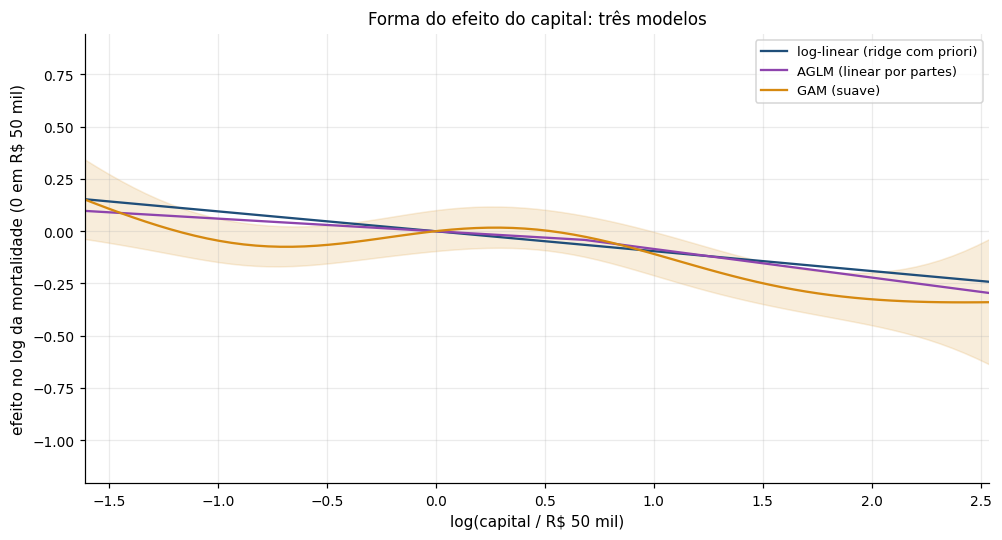

In [7]:
from vgpricing import gam as GA
cap_te = te.assign(capital=cm["capital_referencia"] * np.exp(te["log_capital_c"]))
tab_aglm = M.ajustar_tabela(tr, "AGLM com priori SOA", cm, prioris, {})
te["mu_aglm"] = te["E"] * M.multiplicador_manual(cap_te, tab_aglm)[0]
gm = GA.ajustar_gam(tr, {"teste": te}, ["log_capital_c"], ["cnae_secao"], k=6)
te["mu_gam"] = gm["previsoes"]["teste"]
# forma do efeito do capital: log-linear (ridge com priori), AGLM e GAM, centradas em C = C_ref
tab_ridge = M.ajustar_tabela(tr, "ridge com priori SOA", cm, prioris, {})
lc = np.linspace(tr["log_capital_c"].quantile(0.01), tr["log_capital_c"].quantile(0.99), 200)
cap_grade = pd.DataFrame({"capital": cm["capital_referencia"] * np.exp(lc), "cnae_secao": "C", "cnae_divisao": "x",
                          "faixa_idade": "40-49", "faixa_tamanho": "100-499", "sexo": "M"})
ef = lambda t: np.log(M.multiplicador_manual(cap_grade, t)[0]) - np.log(M.multiplicador_manual(cap_grade.iloc[[np.argmin(np.abs(lc))]], t)[0])
cg = gm["curvas"]["log_capital_c"]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(lc, ef(tab_ridge), color="#1f4e79", label="log-linear (ridge com priori)")
ax.plot(lc, ef(tab_aglm), color="#8e44ad", label="AGLM (linear por partes)")
g0 = np.interp(0, cg["x"], cg["efeito"])
ax.plot(cg["x"], cg["efeito"] - g0, color="#d68910", label="GAM (suave)")
ax.fill_between(cg["x"], cg["efeito"] - g0 - 1.96 * cg["ep"], cg["efeito"] - g0 + 1.96 * cg["ep"], color="#d68910", alpha=0.15)
ax.set_xlim(lc.min(), lc.max())
ax.set_xlabel("log(capital / R$ 50 mil)"); ax.set_ylabel("efeito no log da mortalidade (0 em R$ 50 mil)")
ax.set_title("Forma do efeito do capital: três modelos"); ax.legend()
fig.savefig(RAIZ / "docs/figuras/taxa_manual_forma_capital.png", dpi=110)
plt.show()

Se as três curvas ficam próximas na faixa com dados, a forma log-linear basta e a complexidade do AGLM não se paga;
se o AGLM e o GAM dobram juntos onde a log-linear é reta, a forma importa. O teste fora do tempo (seção 5) decide.

**Onde o LightGBM vê estrutura** (média do |SHAP| e SHAP por nível, como na SOA 4.2.4), e o **fechamento do ciclo**:
a interação mais forte da tabela vira uma hipótese concreta, testada no próprio GLMM por razão de verossimilhança.
Uma hipótese dirigida tem muito mais poder que a busca às cegas do LightGBM (o notebook 90 mede isso).

,média |SHAP|
cnae_secao,0.0651
sexo,0.0286
log_capital_c,0.0273
faixa_tamanho,0.0061
faixa_idade,0.0033


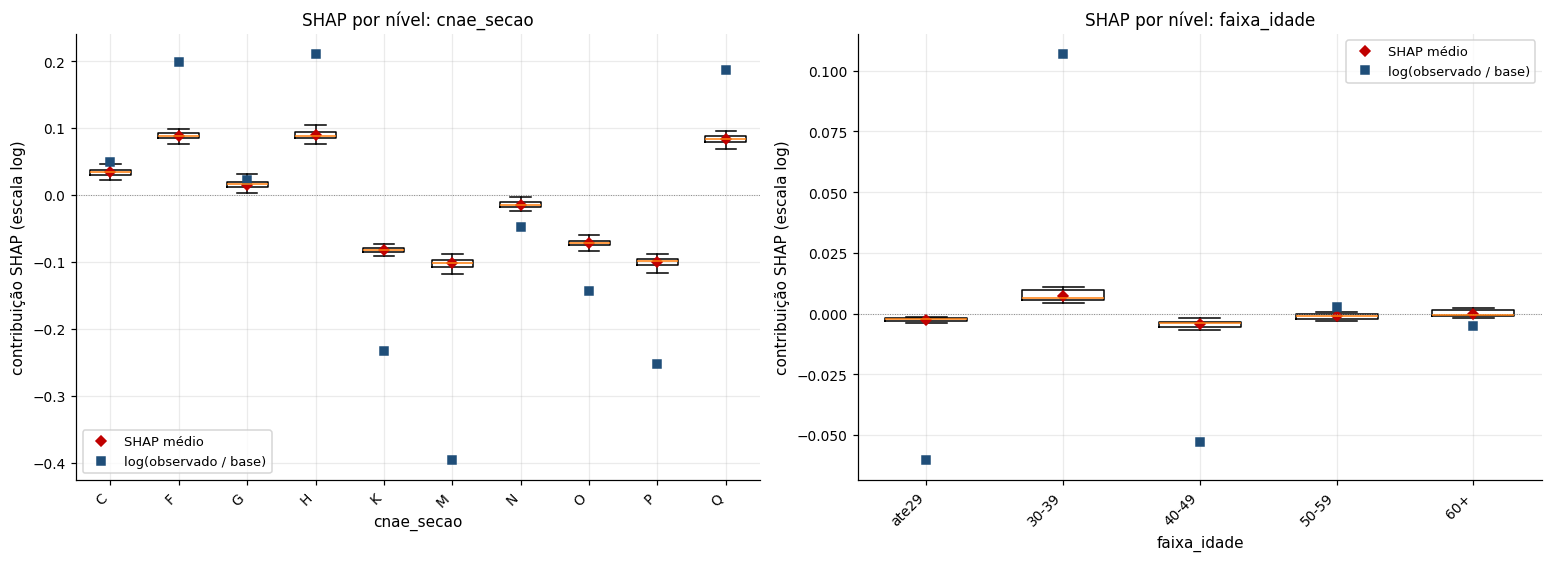

In [8]:
Xs = D._matriz(tr, VL, CL, lg["niveis"])
contrib = D.contribuicoes(lg["modelo"], Xs)
display(D.importancia(contrib, tr["E"].to_numpy()).to_frame("média |SHAP|"))
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, v, ordem in zip(axs, ["cnae_secao", "faixa_idade"], [None, cm["faixas"]["idade"]["rotulos"]]):
    D.grafico_shap(ax, contrib, tr.assign(mu_manual=tr["E"]), v, ordem=ordem)
plt.show()

In [9]:
a, b = TOP[0].split(":")
categ = [x for x in (a, b) if x in CL]
teste_dirigido = D.testar_candidato_glmm(tr, cm, FIXOS, [TOP[0]], categoricas_extras=[c for c in categ if c != "cnae_secao"])
print(f"Interação testada no GLMM: {TOP[0]}")
teste_dirigido[["termo", "lr", "gl", "p_valor"]]

Interação testada no GLMM: log_capital_c:sexo


,termo,lr,gl,p_valor
0,log_capital_c:sexo,2.5537,2,0.2789


Se o p-valor não for pequeno, a interação apontada pelo LightGBM não se sustenta como fator de tarifa nesta carteira,
e a taxa manual fica com os efeitos principais. Se for, ela entra como candidata, com a mesma regra de decisão.

## 6. Comparação no teste (2024)

In [10]:
te["mu_plano"] = te["E"] * tr["N"].sum() / tr["E"].sum()
PREV = {"plano atual (tábua × A/E)": "mu_plano", "GLM": "mu_glm", "GLMM": "mu_glmm", "ridge com priori SOA": "mu_ridge",
        "AGLM com priori SOA": "mu_aglm", "GAM": "mu_gam", "elastic net + interações": "mu_en", "LightGBM": "mu_lgbm"}
m = A.metricas(te, PREV)
m["Gini"] = [A.lorenz_gini(te, c)[1] for c in PREV.values()]
m["papel"] = ["tarifa" if n in cm["decisao"]["ordem_preferencia"] else "referência" for n in PREV]
m

,modelo,deviance,MSE,MAE,A/M total,deviance vs melhor,Gini,papel
0,plano atual (tábua × A/E),"1,730.3125",0.1008,0.1125,0.9645,26.1616,-0.0944,tarifa
1,GLM,"1,705.2934",0.0971,0.1101,0.9646,1.1425,0.1188,tarifa
2,GLMM,"1,714.5843",0.0980,0.1112,0.9511,10.4333,0.0984,tarifa
3,ridge com priori SOA,"1,716.6660",0.0985,0.1106,0.9641,12.5150,0.0865,tarifa
4,AGLM com priori SOA,"1,704.1510",0.0966,0.1099,0.9652,0.0000,0.1305,tarifa
5,GAM,"1,706.0459",0.0970,0.1098,0.9669,1.8950,0.1174,referência
6,elastic net + interações,"1,707.3588",0.0983,0.1113,0.9684,3.2079,0.1339,referência
7,LightGBM,"1,706.4317",0.0974,0.1102,0.9827,2.2807,0.1467,referência


In [11]:
TARIFA = {n: c for n, c in PREV.items() if n in cm["decisao"]["ordem_preferencia"]}
melhor = m[m["papel"] == "tarifa"].sort_values("deviance").iloc[0]["modelo"]
vs = A.comparar_modelos(te, PREV, melhor, unidade="id_estipulante", n_boot=cm["decisao"]["bootstrap"])
escolhido, empatados = M.escolher_modelo(vs[vs["modelo"].isin(TARIFA)], cm["decisao"]["ordem_preferencia"])
ref_melhor = vs[(~vs["modelo"].isin(TARIFA)) & vs["significativa"] & (vs[f"diferença vs {melhor}"] < 0)]
print(f"Menor deviance entre os candidatos a tarifa: {melhor}")
print(f"Empatados com ele: {empatados}  ->  escolhido pela ordem de preferência: {escolhido}")
print("Referência significativamente melhor que o melhor candidato:", ref_melhor["modelo"].tolist() or "nenhuma")
piores = vs[vs["significativa"] & (vs[f"diferença vs {melhor}"] > 0)]["modelo"].tolist()
print("Significativamente piores que o melhor candidato:", piores or "nenhum")
vs.assign(papel=vs["modelo"].map(lambda n: "tarifa" if n in TARIFA else "referência"), escolhido=vs["modelo"] == escolhido) \
  .to_csv(RAIZ / "resultados/taxa_manual_comparacao_teste.csv", index=False)
vs

Menor deviance entre os candidatos a tarifa: AGLM com priori SOA
Empatados com ele: ['GLM', 'AGLM com priori SOA']  ->  escolhido pela ordem de preferência: GLM
Referência significativamente melhor que o melhor candidato: nenhuma
Significativamente piores que o melhor candidato: ['plano atual (tábua × A/E)', 'GLMM', 'ridge com priori SOA']


,modelo,deviance,diferença vs AGLM com priori SOA,IC95 inf,IC95 sup,significativa
0,plano atual (tábua × A/E),333.2682,22.3658,4.9629,41.3627,True
1,GLM,310.9474,0.0450,-12.5509,11.6172,False
2,GLMM,321.1447,10.2423,1.0091,19.9891,True
3,ridge com priori SOA,323.0164,12.1140,0.7129,24.9969,True
4,AGLM com priori SOA,310.9024,0.0000,0.0000,0.0000,False
5,GAM,312.6591,1.7567,-11.3727,13.7823,False
6,elastic net + interações,310.6510,-0.2514,-14.2008,13.8127,False
7,LightGBM,312.0212,1.1188,-7.3495,9.9886,False


A tabela separa o que o teste já distingue (IC da diferença sem o zero) do que fica empatado; entre os empatados
com o melhor, vale a ordem de preferência fixada antes. Duas leituras:
- Se o **plano atual** fica significativamente atrás, modelar capital e atividade melhora o preço de forma comprovada,
  não só em tese.
- Os efeitos fixos de um **GLMM** são condicionais ao grupo; como taxa de grupo novo, podem prever pior que o GLM
  mesmo com AIC melhor no treino. O efeito de grupo continua útil onde ele pertence: na credibilidade da renovação.

Se nenhuma referência (LightGBM, elastic net com interações) ganha com significância, não há sinal de estrutura
faltando que justifique ir além de capital e seção.

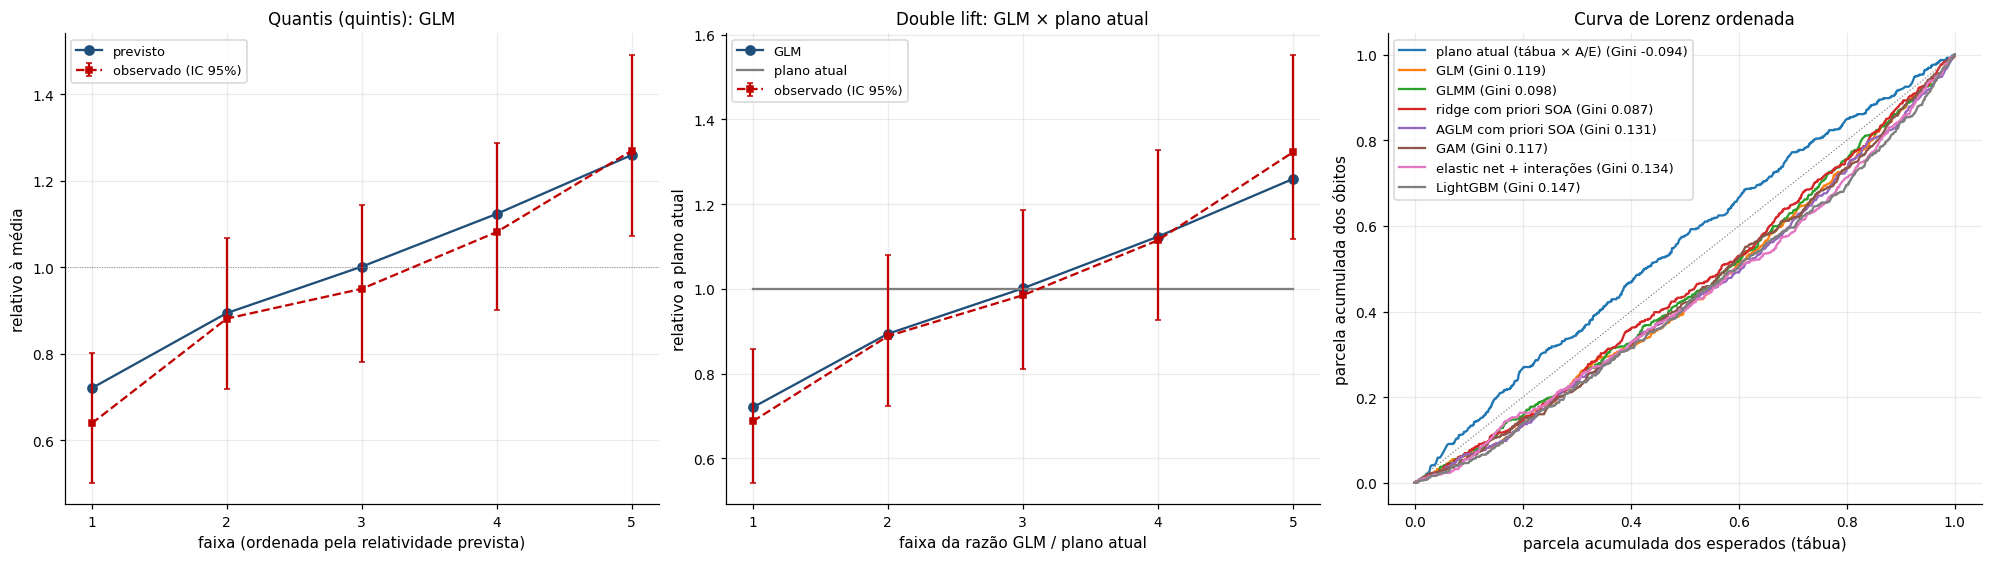

,variável,nível,N,mu_glm,A/M,A/M inf,A/M sup,IC exclui 100%
0,faixa_capital,150-400k,71,83.0683,0.8547,0.6675,1.0781,False
1,faixa_capital,30-60k,196,208.9873,0.9379,0.8111,1.0787,False
2,faixa_capital,60-150k,174,169.3657,1.0274,0.8804,1.1919,False
3,faixa_capital,acima400k,17,13.5866,1.2512,0.7289,2.0034,False
4,faixa_capital,ate30k,104,107.6446,0.9661,0.7894,1.1706,False
0,cnae_secao,C,90,99.4445,0.9050,0.7277,1.1124,False
1,cnae_secao,F,59,62.5529,0.9432,0.7180,1.2167,False
2,cnae_secao,G,52,62.9946,0.8255,0.6165,1.0825,False
3,cnae_secao,H,100,97.2603,1.0282,0.8366,1.2505,False
4,cnae_secao,K,7,15.6140,0.4483,0.1802,0.9237,True


In [12]:
col = {'ridge com priori SOA': 'mu_ridge', 'AGLM com priori SOA': 'mu_aglm', 'GLMM': 'mu_glmm', 'GLM': 'mu_glm', 'plano atual (tábua × A/E)': 'mu_plano'}[escolhido]
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
A.grafico_quantis(ax[0], A.quantis(te, col, n=5), f"Quantis (quintis): {escolhido}")
A.grafico_double_lift(ax[1], A.double_lift(te, col, "mu_plano", n=5), escolhido, "plano atual")
A.grafico_lorenz(ax[2], {n: A.lorenz_gini(te, c) for n, c in PREV.items()})
fig.savefig(RAIZ / "docs/figuras/taxa_manual_teste.png", dpi=110)
plt.show()
am = pd.concat([A.tabela_am(te, v, col).rename(columns={v: "nível"}).assign(variável=v) for v in ["faixa_capital", "cnae_secao"]])
am[["variável", "nível", "N", col, "A/M", "A/M inf", "A/M sup", "IC exclui 100%"]]

Quintis em vez de decis: com ~500 óbitos, decis teriam ~50 óbitos cada e intervalos largos demais.

## 7. Reajuste com toda a experiência e tabela de fatores

In [13]:
tudo, itudo = base(None)
meta = {"gerado_em": pd.Timestamp.today().date().isoformat(), "fonte_dados": "carteira sintética",
        "tabua": tabua.nome, "tabua_sha256": tabua.sha256, "corte_experiencia": itudo["corte_experiencia"],
        "obitos": itudo["obitos"], "esperados_tabua": round(itudo["esperados"], 2),
        "teste_fora_do_tempo": f"{ite['inicio_experiencia']} a {ite['corte_experiencia']}",
        "anos_excluidos_experiencia": itudo["anos_excluidos"],
        "candidatos_empatados_no_teste": empatados, "secoes_agrupadas_em_OUTRAS": itudo["secoes_agrupadas_em_OUTRAS"]}
from vgpricing.ibnr import fator_desenvolvimento
fd = fator_desenvolvimento(dados["sinistros"], cfg["data_referencia"], itudo["corte_experiencia"],
                           excluir_anos=tuple(cm["excluir_anos_experiencia"]))
tabela = M.ajustar_tabela(tudo, escolhido, cm, prioris, meta, fator_desenvolvimento=fd)
print(f"Fator de desenvolvimento (IBNR residual da experiência): {fd:.4f}")
M.salvar_tabela(tabela, RAIZ / "artefatos/fatores_manual.yaml")
print(f"Modelo: {escolhido} | A/E base: {tabela['ae_base']:.4f} | elasticidade ao capital: {tabela['capital']['elasticidade']:.4f}")
pd.Series(tabela["secao"]).sort_values().to_frame("fator de seção (base = 1)")

Fator de desenvolvimento (IBNR residual da experiência): 1.0022
Modelo: GLM | A/E base: 1.0899 | elasticidade ao capital: -0.0673


,fator de seção (base = 1)
M,0.6417
K,0.6678
P,0.7351
O,0.8869
N,0.9238
G,0.9544
C,1.0000
F,1.1669
Q,1.1942
H,1.2105


## 8. Estabilidade dos fatores (CAS 6.4)

A ridge não tem erro-padrão. A estabilidade é medida por **bootstrap por estipulante**: reamostram-se os grupos com
reposição, a tarifa é reajustada pelo mesmo método, e a variação dos fatores mostra quanto eles dependem de quais
grupos estão na carteira. Fatores que mudam muito entre reamostras são instáveis e não deveriam ser usados como estão.

In [14]:
from joblib import Memory
cache = Memory(RAIZ / "data/processed/cache", verbose=0).cache

# cada reamostra fica no cache: interromper e reexecutar não perde o progresso
boot = pd.DataFrame([cache(M.reamostra_fatores)(tudo, escolhido, cm, prioris, cm["validacao_cruzada"]["semente"] + b) for b in range(30)])
estab = pd.DataFrame({"tabela": {"elasticidade": tabela["capital"]["elasticidade"],
                                 **{f"seção {k}": tabela["ae_base"] * v for k, v in tabela["secao"].items()}},
                      "p2,5": boot.quantile(0.025), "p97,5": boot.quantile(0.975)}).dropna()
estab["amplitude relativa"] = (estab["p97,5"] - estab["p2,5"]) / estab["tabela"].abs()
secs = estab.drop(index="elasticidade")
print(f"Elasticidade negativa em {(boot['elasticidade'] < 0).mean():.0%} das reamostras "
      f"(intervalo {estab.loc['elasticidade', 'p2,5']:.3f} a {estab.loc['elasticidade', 'p97,5']:.3f}); "
      f"amplitude mediana dos fatores de seção (nível x seção): {secs['amplitude relativa'].median():.0%}")
estab.sort_values("amplitude relativa")

Elasticidade negativa em 90% das reamostras (intervalo -0.141 a 0.003); amplitude mediana dos fatores de seção (nível x seção): 38%


,tabela,"p2,5","p97,5",amplitude relativa
seção C,1.0899,0.9696,1.1878,0.2002
seção N,1.0068,0.8945,1.1423,0.2461
seção G,1.0402,0.9111,1.2356,0.3120
seção H,1.3194,1.1064,1.5633,0.3463
seção M,0.6994,0.6085,0.8607,0.3606
seção F,1.2718,0.9868,1.4897,0.3954
seção Q,1.3016,0.8613,1.5037,0.4936
seção O,0.9667,0.6731,1.2558,0.6029
seção P,0.8012,0.6276,1.1208,0.6156
seção K,0.7278,0.5124,1.0435,0.7298


Os fatores estão em escala absoluta (nível × seção), que é o que entra no preço. A leitura é a do resumo impresso:
o **sinal** da elasticidade ao capital é estável se ela fica negativa em praticamente todas as reamostras, mesmo
com amplitude larga; seções com amplitude muito acima da mediana dependem de poucos grupos e são as primeiras a
revisar quando a base crescer. Seções só com a priori da SOA variam apenas com o nível. (30 reamostras dão uma ordem
de grandeza; para a nota técnica, usar mais.)

## 9. Exemplo: taxa pura manual de um grupo

In [15]:
ref = pd.Timestamp(cfg["data_referencia"])
ativos = dados["vidas"][dados["vidas"]["data_fim"].isna()]
porte = ativos["id_estipulante"].value_counts()
grupo = porte.index[len(porte) // 2]
censo = ativos[ativos["id_estipulante"] == grupo]
e = dados["estipulantes"].set_index("id_estipulante").loc[grupo]
cot = M.taxa_pura_manual(censo, e["cnae_secao"], e["cnae_divisao"], tabela, tabua, ref + pd.Timedelta(days=1))
pd.Series({"estipulante": grupo, "atividade": f"{e['cnae_secao']}:{e['cnae_divisao']}", "vidas": cot["vidas"],
           "capital total (R$)": cot["capital_total"], "fator de atividade": cot["fator_atividade"],
           "prêmio puro anual (R$)": cot["premio_puro_anual"], "taxa pura mensal (‰)": cot["taxa_pura_mensal_mil"],
           "avisos": "; ".join(cot["avisos"]) or "nenhum"}).to_frame("cotação")

,cotação
estipulante,EST0013
atividade,G:46
vidas,468
capital total (R$),"90,145,600.0000"
fator de atividade,0.9544
prêmio puro anual (R$),"120,159.5929"
taxa pura mensal (‰),0.1111
avisos,divisão sem experiência ['G:46']: usada a médi...


## Limitações
- **Um ano de teste com ~500 óbitos** não separa os candidatos: a escolha vem da ordem de preferência fixada antes.
  Na base real, com mais volume, o mesmo procedimento pode separar.
- **Carteira sintética:** os números refletem as hipóteses do gerador; a verificação de que o código recupera a
  verdade está no notebook 90.
- **Priori:** forma americana (2010–2013), mapeada para CNAE por julgamento; o lambda decide quanto a carteira se
  afasta dela.